# Module 4 — NumPy, pandas, SQL and Visualization
### मॉड्यूल 4 — NumPy, pandas, SQL और Visualization

> **Phase 1 · Foundations** · NumPy 2.x, pandas 3.x, sqlite3 (built in), matplotlib, optional plotly/pyarrow/openpyxl.
> Data: Titanic, Penguins, Flights (monthly airline passengers 1949–60), Tips, and a seeded *synthetic* retail sales dataset (clearly marked; generated in code so it's reproducible).

## 0. Module map

| # | Lesson | Outcome |
|---|---|---|
| 4.1 | NumPy: arrays, shape/dtype, indexing, broadcasting, vectorization, random, linear algebra | Replace Python loops with 100× faster array code |
| 4.2 | pandas: loading CSV/Excel/JSON/Parquet, Series/DataFrame, select/filter/sort/mask | Answer any "which rows…?" question in one line |
| 4.3 | Cleaning: missing values, duplicates, dtypes, dates and strings | Turn a messy export into an analysis-ready table |
| 4.4 | groupby/aggregation, merge/join/concat, pivot/melt | Build any summary table a manager asks for |
| 4.5 | SQL: keys, SELECT/WHERE, GROUP BY/HAVING, JOINs, subqueries, CTEs, window functions, indexes | Query a database and explain the query plan |
| 4.6 | Visualization: matplotlib essentials, chart choice, plotly interactive | Pick the right chart and make it honest |
| ★ | Mini-project: **Complete Sales Analysis** — load, clean, explore, visualize, insight report | A reproducible analysis with 5 business insights |

```mermaid
flowchart LR
    SRC[CSV / Excel / JSON / Parquet / SQL DB / API] --> PD[pandas DataFrame]
    NP[NumPy arrays: vectorized math] --> PD
    PD --> CL[Clean: missing, dupes, types, dates, strings]
    CL --> AG[groupby / merge / pivot]
    DB[(SQLite)] -- SQL: SELECT, JOIN, CTE, WINDOW --> AG
    AG --> VZ[matplotlib / plotly]
    VZ --> REP[Insight report]
```

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt   # in a plain script without a display, set MPLBACKEND=Agg

def find_data() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for c in (p / "datasets", p / "tutorials" / "data-science-ai" / "datasets"):
            if (c / "titanic.csv").exists():
                return c
    raise FileNotFoundError("Set DATA = Path('<path>/datasets')")

DATA = find_data()
rng = np.random.default_rng(7)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


---

## Lesson 4.1 — NumPy: arrays, broadcasting and vectorization
### पाठ 4.1 — NumPy: arrays, broadcasting और vectorization

**a. Concept (EN).** An `ndarray` is a contiguous block of same-typed numbers with a **shape** (dimensions), **dtype** (`float64`, `int32`, `bool`…) and **strides**. Operations run in compiled C over the whole block (**vectorization**), so `a * 2` on 1 M numbers is ~100× faster than a Python loop. **Indexing**: `a[i]`, slices `a[1:5]` (views, not copies!), boolean masks `a[a > 0]`, fancy indexing `a[[0, 3]]` (copies). **Axis**: `sum(axis=0)` collapses rows (per-column result). **Broadcasting**: shapes are compared from the right; dimensions match if equal or 1 → `(333, 4) - (4,)` subtracts the column means from every row. Random numbers: `np.random.default_rng(seed)`. Linear algebra: `@`, `np.linalg.solve`, `lstsq`.

**a. Concept (HI).** NumPy array एक ही type के numbers का लगातार block है — shape, dtype के साथ। पूरा काम C में एक साथ होता है (vectorization), इसलिए Python loop से 100 गुना तेज़। Slice एक *view* है — उसे बदलोगे तो original भी बदलेगा! `axis=0` मतलब rows को समेटो (हर column का जवाब)। Broadcasting: shapes को दाईं ओर से मिलाओ — बराबर हों या 1 हो तो चलेगा।

**b. Analogy.** A Python list is a *bag of mixed groceries* (each item wrapped separately); a NumPy array is an *egg tray* — identical slots, so a machine can wash all eggs at once. Broadcasting = adding the same masala to every plate in a row without making copies of the masala.

**c. Math, worked.** Standardising: Z = (X − μ)/σ where X is (n×d), μ and σ are (d,). Broadcasting stretches (d,) to (n×d). Vectorized regression: β = lstsq(X, y). Mean/variance/cosine from scratch: μ = Σx/n, σ² = Σ(x−μ)²/n, cos = a·b/(‖a‖‖b‖).

In [2]:
import time
peng = pd.read_csv(DATA / "penguins.csv").dropna()
X = peng[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].to_numpy()
print("shape", X.shape, "| dtype", X.dtype, "| ndim", X.ndim, "| bytes", X.nbytes)

# Indexing, masks, views vs copies
print("first row:", X[0], "| mass of first 3:", X[:3, 3])
heavy = X[X[:, 3] > 5500]                         # boolean mask -> copy
print("heavy penguins:", len(heavy))
view = X[:2, :2]; view_copy = X[:2, :2].copy()
print("is view sharing memory?", np.shares_memory(view, X), "| copy?", np.shares_memory(view_copy, X))

# Axis + broadcasting: standardise every column in one line
mu, sd = X.mean(axis=0), X.std(axis=0)
Z = (X - mu) / sd                                 # (333,4) - (4,) -> broadcast
print("Z means≈0:", Z.mean(0).round(6), "| Z std≈1:", Z.std(0).round(6))

# Vectorization speed-up
big = rng.standard_normal(1_000_000)
t0 = time.perf_counter(); s_loop = sum(v * v for v in big); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); s_vec = np.dot(big, big); t_vec = time.perf_counter() - t0
print(f"loop {t_loop*1e3:.0f} ms vs vectorized {t_vec*1e3:.2f} ms -> {t_loop/t_vec:.0f}x faster, equal: {np.isclose(s_loop, s_vec)}")

# From scratch: mean, variance, cosine, then a vectorized linear-regression fit
m = X[:, 3]
print("mean", m.sum() / m.size, "var", ((m - m.mean())**2).sum() / m.size, "np.var", m.var())
a, b = Z[0], Z[1]; print("cosine row0,row1:", round(a @ b / np.sqrt((a @ a) * (b @ b)), 4))
A = np.column_stack([np.ones(len(X)), X[:, :3]])
beta, *_ = np.linalg.lstsq(A, X[:, 3], rcond=None)
print("vectorized fit beta:", beta.round(2))

# Random numbers and matrix ops
M = rng.integers(0, 10, (3, 3)); print("M @ M.T symmetric?", np.allclose(M @ M.T, (M @ M.T).T))

shape (333, 4) | dtype float64 | ndim 2 | bytes 10656
first row: [  39.1   18.7  181.  3750. ] | mass of first 3: [3750. 3800. 3250.]
heavy penguins: 28
is view sharing memory? True | copy? False
Z means≈0: [ 0.  0.  0. -0.] | Z std≈1: [1. 1. 1. 1.]
loop 87 ms vs vectorized 0.32 ms -> 268x faster, equal: True
mean 4207.057057057057 var 646425.4231709187 np.var 646425.4231709187
cosine row0,row1: 0.9416
vectorized fit beta: [-6.44548e+03  3.29000e+00  1.78400e+01  5.07600e+01]
M @ M.T symmetric? True


*Hindi summary:* shape/dtype देखे, mask से भारी penguins निकाले, view और copy का फ़र्क देखा। Broadcasting से एक लाइन में standardisation। 10 लाख numbers पर vectorized code loop से सैकड़ों गुना तेज़। Mean, variance, cosine और linear regression — सब vectorized।

**e. Traps.** Modifying a slice and silently changing the original. `(n,)` vs `(n,1)` shapes broadcasting into an (n×n) matrix by accident — check `.shape` constantly. Integer dtype truncation: `np.array([1,2]) / 2` is float but `a //= 2` stays int. Using `np.random.seed` (legacy global state) instead of a `Generator`. Interview: *"Why is NumPy fast?"* Contiguous typed memory, compiled loops, SIMD, BLAS for linear algebra, no per-element Python object overhead.

**f. Memory.** Mnemonic **"Right-align, 1 stretches"** (broadcasting). **याद रखो:** *"Slice = खिड़की (view), copy = फ़ोटो।"*

| Q | A |
|---|---|
| `axis=0` reduces over? | Rows → one value per column |
| Broadcasting rule? | Compare from the right; equal or 1 |
| Slice: view or copy? | View |
| Boolean mask result? | Copy |
| Modern RNG? | `np.random.default_rng(seed)` |

**g. Practice.** (1) Min-max scale every column of X to [0,1] with broadcasting. (2) Compute the (333×333) Euclidean distance matrix without loops. (3) Count penguins whose every standardised feature is within ±1.

**Solutions / हल**

In [3]:
mm = (X - X.min(0)) / (X.max(0) - X.min(0)); print("1:", mm.min(0), mm.max(0))
D = np.sqrt(((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1)); print("2:", D.shape, D[0, :3].round(2))
print("3:", int(np.all(np.abs(Z) <= 1, axis=1).sum()))

1: [0. 0. 0. 0.] [1. 1. 1. 1.]
2: (333, 333) [0.   0.76 1.25]
3: 51


**h. Quiz.** 1) Shape of (5,1) + (3,)? 2) `np.arange(6).reshape(2,3).sum(axis=1)`? 3) Is `a[[0,2]]` a view? 4) dtype of `np.array([1, 2.5])`? 5) Why prefer `lstsq` over `inv`?

**Answers**1) (5,3). 2) [3, 12]. 3) No — fancy indexing copies. 4) float64. 5) More numerically stable, handles rank deficiency.

---

## Lesson 4.2 — pandas: loading, Series/DataFrame, selecting and filtering
### पाठ 4.2 — pandas: data load करना, Series/DataFrame, select और filter

**a. Concept (EN).** A **Series** = 1-D labelled array (index + values + dtype). A **DataFrame** = dict of Series sharing an index. Loaders: `read_csv`, `read_excel` (openpyxl), `read_json`, `read_parquet` (pyarrow; columnar, typed, compressed — the analytics default), `read_sql`. **Selection**: `df["col"]`, `df[["a","b"]]`; `.loc[row_labels, col_labels]` (label-based, *inclusive* slices); `.iloc[i, j]` (position-based, exclusive). **Filtering** with boolean masks: `df[(df.age > 30) & (df.sex == "male")]` (use `&`, `|`, `~` with parentheses) or `df.query("age > 30 and sex == 'male'")`. **Sorting**: `sort_values(["pclass","fare"], ascending=[True, False])`. pandas 3 uses **Copy-on-Write**: chained assignment like `df[df.x > 0]["y"] = 1` never modifies `df` — use `df.loc[mask, "y"] = 1`.

**a. Concept (HI).** Series = एक labelled column, DataFrame = कई Series का table। CSV, Excel, JSON, Parquet — सब के लिए `read_*` functions; Parquet analytics के लिए सबसे अच्छा (typed, compressed)। `.loc` label से चुनता है (slice में आख़िरी भी शामिल), `.iloc` position से। Filter के लिए boolean mask, `&`/`|` और brackets के साथ। pandas 3 में Copy-on-Write है — बदलाव हमेशा `df.loc[mask, "col"] = value` से करो।

**b. Analogy.** DataFrame = an Excel sheet with superpowers. `.loc` = finding a student by roll number; `.iloc` = "the 5th student in the line". A boolean mask = a sieve (*chhalni*) that keeps only the rows you want.

**c. Math.** A filter is set intersection on row indices: rows(A & B) = rows(A) ∩ rows(B). Selectivity = |filtered| / |total| — high-selectivity filters are what database indexes accelerate (Lesson 4.5).

In [4]:
import io, json, tempfile
t = pd.read_csv(DATA / "titanic.csv")
print(t.shape); print(t.dtypes.value_counts().to_dict())
print(t.head(3)[["survived", "pclass", "sex", "age", "fare"]])

# Round-trip through other formats in a temp folder
tmp = Path(tempfile.mkdtemp())
t.to_json(tmp / "t.json", orient="records"); print("json rows:", len(pd.read_json(tmp / "t.json")))
for fmt, w, r in [("parquet", "to_parquet", pd.read_parquet), ("xlsx", "to_excel", pd.read_excel)]:
    try:
        getattr(t, w)(tmp / f"t.{fmt}", index=False)
        print(f"{fmt}: {(tmp / f't.{fmt}').stat().st_size/1024:.0f} KB, rows {len(r(tmp / f't.{fmt}'))}")
    except ImportError as e:
        print(f"{fmt} skipped (install pyarrow / openpyxl):", e)
print("csv:", round(len(t.to_csv(index=False)) / 1024), "KB")

# Selecting
s = t["fare"]; print(type(s).__name__, s.dtype, s.index[:3].tolist())
print(t.loc[0:2, ["sex", "age"]])                 # inclusive label slice -> 3 rows
print(t.iloc[0:2, 2:4])                           # exclusive position slice -> 2 rows

# Filtering + sorting
rich_women = t[(t.sex == "female") & (t.fare > 100)]
print("rich women:", len(rich_women), "survival", rich_women.survived.mean().round(3))
print(t.query("pclass == 3 and age < 10").survived.mean().round(3), "= 3rd-class kids survival")
print(t.sort_values(["pclass", "fare"], ascending=[True, False]).head(3)[["pclass", "fare", "sex"]])

# Copy-on-Write: the right way to assign
t2 = t.copy(); t2.loc[t2.fare == 0, "fare"] = np.nan
print("zero fares set to NaN:", t2.fare.isna().sum())

(891, 15)
{<StringDtype(na_value=nan)>: 7, dtype('int64'): 4, dtype('float64'): 2, dtype('bool'): 2}
   survived  pclass     sex   age     fare
0         0       3    male  22.0   7.2500
1         1       1  female  38.0  71.2833
2         1       3  female  26.0   7.9250
json rows: 891
parquet: 14 KB, rows 891


xlsx: 49 KB, rows 891
csv: 56 KB
Series float64 [0, 1, 2]
      sex   age
0    male  22.0
1  female  38.0
2  female  26.0
      sex   age
0    male  22.0
1  female  38.0
rich women: 34 survival 0.941
0.452 = 3rd-class kids survival
     pclass      fare     sex
258       1  512.3292  female
679       1  512.3292    male
737       1  512.3292    male
zero fares set to NaN: 15


*Hindi summary:* Titanic को CSV, JSON, Parquet, Excel में लिखा-पढ़ा (Parquet सबसे छोटा)। `.loc` में slice inclusive, `.iloc` में exclusive। Mask और `query` से filter, `sort_values` से sorting, और Copy-on-Write के साथ सही assignment `loc` से।

**e. Traps.** `and`/`or` instead of `&`/`|` → "truth value of a Series is ambiguous". Missing parentheses: `t.sex == "female" & t.fare > 100` fails (precedence). Chained assignment. `read_csv` guessing dtypes wrongly (IDs with leading zeros → use `dtype={"id": str}`). Interview: *"Why Parquet over CSV?"* Columnar (read only needed columns), typed schema, compression, predicate pushdown, splittable for Spark.

**f. Memory.** Mnemonic **"loc = Label, iloc = Integer"**. **याद रखो:** *"Mask में `&`, और हर शर्त अपने bracket में।"*

| Q | A |
|---|---|
| `.loc` slice end inclusive? | Yes |
| Combine masks with? | `&`, `|`, `~` + parentheses |
| Best format for analytics? | Parquet |
| Safe assignment in pandas 3? | `df.loc[mask, col] = v` |
| SQL-like filter string? | `df.query(...)` |

**g. Practice.** (1) Passengers older than 60 who survived — how many? (2) Top 5 heaviest penguins with species and island. (3) Write a filter for "male, 2nd class, embarked at Southampton, age known" and its survival rate.

**Solutions / हल**

In [5]:
print("1:", len(t[(t.age > 60) & (t.survived == 1)]))
print("2:\n", peng.nlargest(5, "body_mass_g")[["species", "island", "body_mass_g"]])
q = t[(t.sex == "male") & (t.pclass == 2) & (t.embark_town == "Southampton") & t.age.notna()]
print("3:", len(q), round(q.survived.mean(), 3))

1: 5
2:
     species  island  body_mass_g
237  Gentoo  Biscoe       6300.0
253  Gentoo  Biscoe       6050.0
297  Gentoo  Biscoe       6000.0
337  Gentoo  Biscoe       6000.0
299  Gentoo  Biscoe       5950.0
3: 90 0.156


**h. Quiz.** 1) `t.iloc[-1]` returns? 2) `t[["age"]]` type? 3) Which reads only some columns fastest? 4) `t.loc[5:7]` returns how many rows (default index)? 5) Is `t.query("fare > 50")` a view you can safely modify?

**Answers**1) Last row as Series. 2) DataFrame. 3) Parquet with `columns=`. 4) 3. 5) Treat it as a new object; use `.copy()` if you'll modify it.

---

## Lesson 4.3 — Cleaning: missing values, duplicates, dates and strings
### पाठ 4.3 — Data cleaning: missing values, duplicates, dates और strings

**a. Concept (EN).** **Missing data**: `isna()`, `notna()`, `dropna(subset=…)`, `fillna(value | method)`. Decide *why* it's missing (MCAR / MAR / MNAR) before choosing a fix; add a "was_missing" flag when missingness is informative. **Duplicates**: `duplicated(subset, keep)`, `drop_duplicates`. **Dtypes**: `astype`, `pd.to_numeric(errors="coerce")`, `category` dtype (memory + speed). **Dates**: `pd.to_datetime`, `.dt.year/.month/.dayofweek`, `resample("MS")`, time deltas. **Strings**: `.str.lower/strip/contains/extract/replace` — vectorized and NaN-aware.

**a. Concept (HI).** पहले पूछो data क्यों missing है — random है या किसी वजह से — फिर तय करो drop करें या भरें। Missing होना खुद एक signal हो सकता है, तो flag column बनाओ। Duplicates हटाओ, सही dtypes लगाओ (`to_numeric(errors="coerce")`), dates को `to_datetime` से असली date बनाओ, और strings पर `.str` methods लगाओ।

**b. Analogy.** Cleaning is *sorting rice before cooking* — remove stones (invalid values), duplicates (two grains stuck), and figure out why some are broken (missingness reason). Skip it and every dish (model) tastes bad.

**c. Math.** Mean imputation shrinks variance: if 20% of a column is filled with the mean, variance drops by ~20% (the filled values contribute 0 deviation). Median imputation is robust to outliers. Group-wise imputation (median age by title/class) preserves structure.

In [6]:
# Build a deliberately messy copy of Titanic
print("identical rows already in Titanic:", t.duplicated().sum(), "-> real people, not dupes! (no ID column)")
raw = t.reset_index(names="passenger_id")                                             # give every person an ID first
raw = pd.concat([raw, raw.sample(15, random_state=1)], ignore_index=True)           # duplicates
raw.loc[raw.sample(10, random_state=2).index, "fare"] = -1                           # invalid
raw["sex"] = raw["sex"].where(rng.random(len(raw)) > 0.1, raw["sex"].str.upper() + " ")  # inconsistent text
print("rows:", len(raw), "| dupes by ID:", raw.passenger_id.duplicated().sum(), "| sex values:", raw.sex.unique()[:4])

clean = (raw.drop_duplicates(subset="passenger_id")
            .assign(sex=lambda d: d.sex.str.strip().str.lower(),
                    fare=lambda d: d.fare.mask(d.fare < 0),                         # invalid -> NaN
                    age_missing=lambda d: d.age.isna().astype(int)))
print("after:", len(clean), "| sex:", clean.sex.unique().tolist(), "| NaN fares:", clean.fare.isna().sum())

# Imputation strategies and their effect on variance
age = clean.age
print(f"var original {age.var():.1f} | mean-filled {age.fillna(age.mean()).var():.1f} | "
      f"group-median-filled {age.fillna(clean.groupby(['pclass','sex']).age.transform('median')).var():.1f}")
clean["age"] = age.fillna(clean.groupby(["pclass", "sex"]).age.transform("median"))
clean["fare"] = clean.fare.fillna(clean.groupby("pclass").fare.transform("median"))
clean["embark_town"] = clean.embark_town.astype("category")
print("missing left:", clean[["age", "fare"]].isna().sum().to_dict(), "| mem category vs str:",
      clean.embark_town.memory_usage(deep=True), "vs", clean.embark_town.astype(str).memory_usage(deep=True))

# Dates: monthly airline passengers
fl = pd.read_csv(DATA / "flights.csv")
fl["date"] = pd.to_datetime(fl.year.astype(str) + "-" + fl.month.astype(str) + "-01", format="%Y-%B-%d")
fl = fl.set_index("date").sort_index()
print(fl.head(2)); print("busiest month name:", fl.passengers.groupby(fl.index.month_name()).mean().idxmax())
print("yearly totals:", fl.passengers.resample("YS").sum().iloc[[0, -1]].to_dict())

# Strings: extract a deck letter from a fake cabin code
cabins = pd.Series(["C85", "C123", None, "E46", "B57 B59"])
print(cabins.str.extract(r"^([A-Z])")[0].tolist(), cabins.str.contains("B", na=False).tolist())

identical rows already in Titanic: 107 -> real people, not dupes! (no ID column)
rows: 906 | dupes by ID: 15 | sex values: <ArrowStringArray>
['male', 'female', 'FEMALE ', 'MALE ']
Length: 4, dtype: str
after: 891 | sex: ['male', 'female'] | NaN fares: 10
var original 211.0 | mean-filled 169.1 | group-median-filled 177.0
missing left: {'age': 0, 'fare': 0} | mem category vs str: 1078 vs 16738
            year     month  passengers
date                                  
1949-01-01  1949   January         112
1949-02-01  1949  February         118
busiest month name: July
yearly totals: {Timestamp('1949-01-01 00:00:00'): 1520, Timestamp('1960-01-01 00:00:00'): 5714}
['C', 'C', nan, 'E', 'B'] [False, False, False, False, True]


*Hindi summary:* जानबूझकर गंदा data बनाया — duplicates, negative fares, " MALE " जैसी गड़बड़ strings — और एक chain में साफ़ किया। Mean से भरने पर variance सबसे ज़्यादा घटता है; group median बेहतर। `category` dtype memory बचाता है। Flights में dates बनाकर सबसे busy महीना (July) और सालाना total निकाला। `.str.extract` से regex।

**e. Traps.** `drop_duplicates()` on a table without an ID — Titanic has ~100 identical-looking rows that are different people; deduplicate on a key. Dropping all rows with any NaN (lose 80% of Titanic because of `deck`). Imputing using the *whole* dataset before train/test split → leakage (Module 5). `to_datetime` without `format` → slow and ambiguous (01/02 = Jan 2 or Feb 1?). Comparing strings with trailing spaces. Interview: *"MCAR vs MAR vs MNAR?"* Missing completely at random; at random given observed data; not at random (depends on the missing value itself — e.g., high earners skip the income question).

**f. Memory.** Mnemonic **"D-I-T-D-S: Dupes, Invalid, Types, Dates, Strings"** — the cleaning checklist. **याद रखो:** *"Missing क्यों है — पहले ये पूछो, फिर भरो।"*

| Q | A |
|---|---|
| Convert bad numbers to NaN? | `pd.to_numeric(errors="coerce")` |
| Effect of mean imputation on variance? | Shrinks it |
| Memory-efficient low-cardinality text? | `category` dtype |
| Monthly totals from daily? | `resample("MS").sum()` |
| Missing depends on its own value? | MNAR |

**g. Practice.** (1) Which Titanic column has the most missing values, and should you drop it? (2) Add a `weekday` column to a range of 10 dates starting 2024-01-01. (3) Compute month-over-month % change of flights passengers and the largest jump.

**Solutions / हल**

In [7]:
print("1:", t.isna().mean().idxmax(), f"{t.isna().mean().max():.0%} missing - drop or keep only 'has_deck' flag")
d = pd.DataFrame({"date": pd.date_range("2024-01-01", periods=10)}); d["weekday"] = d.date.dt.day_name()
print("2:", d.weekday.tolist()[:3])
pct = fl.passengers.pct_change(); print("3:", pct.idxmax().date(), f"{pct.max():.1%}")

1: deck 77% missing - drop or keep only 'has_deck' flag
2: ['Monday', 'Tuesday', 'Wednesday']
3: 1954-03-01 25.0%


**h. Quiz.** 1) `df.dropna(subset=["age"])` drops? 2) Default `keep` in `drop_duplicates`? 3) `.dt` accessor needs what dtype? 4) Why add `age_missing`? 5) `"B57 B59"` → `str.extract(r"^([A-Z])")` gives?

**Answers**1) Rows where age is NaN. 2) "first". 3) datetime64. 4) Missingness may carry signal (Titanic: missing age correlates with lower survival). 5) "B".

---

## Lesson 4.4 — groupby, merge/join/concat and pivot
### पाठ 4.4 — groupby, merge/join/concat और pivot

**a. Concept (EN).** **groupby = split → apply → combine**. `df.groupby(keys).agg(name=("col", "func"))` (named aggregation); `transform` returns a same-length result (for group-wise features); `filter` keeps whole groups. **merge** = SQL join: `how="inner|left|right|outer"`, `on`, `validate="one_to_many"` to catch duplicate keys, `indicator=True` to audit. **concat** stacks frames vertically/horizontally. **pivot_table** (long → wide, with aggregation) and **melt** (wide → long). `pd.crosstab` = counts of two categoricals.

**a. Concept (HI).** groupby = तोड़ो → हर group पर काम करो → जोड़ो। `agg` summary देता है, `transform` हर row के लिए group की value (features बनाने में काम आता है)। `merge` SQL join जैसा है — `validate` से duplicate keys की गलती पकड़ो। `concat` frames को ऊपर-नीचे जोड़ता है। `pivot_table` long से wide, `melt` wide से long।

**b. Analogy.** groupby = a teacher sorting answer sheets into piles by section, computing each pile's average, and writing one summary line per section. merge = matching the attendance register with the marks register by roll number.

**c. Math.** Join sizes: inner ≤ min(|A|,|B|) *only if keys are unique*; with duplicate keys, an m-to-n join yields Σₖ mₖ·nₖ rows — the classic "row explosion" bug. Weighted mean per group = Σ(wᵢxᵢ)/Σwᵢ.

In [8]:
# Named aggregation
summary = (t.groupby(["pclass", "sex"], observed=True)
             .agg(n=("survived", "size"), survival=("survived", "mean"), avg_fare=("fare", "mean"))
             .round(3))
print(summary)

# transform: group-wise feature for every row
t["fare_vs_class"] = t.fare / t.groupby("pclass").fare.transform("median")
print(t[["pclass", "fare", "fare_vs_class"]].head(3).round(2))

# merge with validation and indicator
classes = pd.DataFrame({"pclass": [1, 2, 3], "deck_level": ["upper", "middle", "lower"], "crew_ratio": [0.5, 0.3, 0.1]})
m = t.merge(classes, on="pclass", how="left", validate="many_to_one", indicator=True)
print(m._merge.value_counts().to_dict(), m.shape)

# Row explosion demo: duplicate key on the right side
bad = pd.concat([classes, classes.iloc[[0]]])
try:
    t.merge(bad, on="pclass", validate="many_to_one")
except pd.errors.MergeError as e:
    print("caught:", str(e)[:60])
print("unvalidated rows:", len(t.merge(bad, on="pclass")), "vs", len(t))

# concat + pivot_table + melt + crosstab
part1, part2 = t.iloc[:400], t.iloc[400:]
print("concat back:", len(pd.concat([part1, part2], ignore_index=True)))
wide = peng.pivot_table(index="species", columns="island", values="body_mass_g", aggfunc="mean").round(0)
print(wide)
long = wide.reset_index().melt(id_vars="species", var_name="island", value_name="mass").dropna()
print(long.head(3))
print(pd.crosstab(t.embark_town, t.pclass, normalize="index").round(2))

                 n  survival  avg_fare
pclass sex                            
1      female   94     0.968   106.126
       male    122     0.369    67.226
2      female   76     0.921    21.970
       male    108     0.157    19.742
3      female  144     0.500    16.119
       male    347     0.135    12.662
   pclass   fare  fare_vs_class
0       3   7.25           0.90
1       1  71.28           1.18
2       3   7.92           0.98
{'both': 891, 'left_only': 0, 'right_only': 0} (891, 19)
caught: Merge keys are not unique in right dataset; not a many-to-on
unvalidated rows: 1107 vs 891
concat back: 891
island     Biscoe   Dream  Torgersen
species                             
Adelie     3710.0  3701.0     3709.0
Chinstrap     NaN  3733.0        NaN
Gentoo     5092.0     NaN        NaN
  species  island    mass
0  Adelie  Biscoe  3710.0
2  Gentoo  Biscoe  5092.0
3  Adelie   Dream  3701.0
pclass          1     2     3
embark_town                  
Cherbourg    0.51  0.10  0.39
Queensto

*Hindi summary:* Named aggregation से (class, sex) summary; `transform` से हर passenger का fare उसकी class के median के मुकाबले। `merge` में `validate` ने duplicate key की गलती पकड़ी — वरना rows बढ़ जातीं। `pivot_table`, `melt`, `crosstab` से reshaping।

**e. Traps.** Joining on keys with different dtypes (`"1"` vs `1`) → zero matches. Row explosion from duplicate keys (always `validate`). `groupby` drops NaN keys by default (`dropna=False` to keep). Using `apply` with Python functions when a vectorized `agg` exists (slow). Interview: *"transform vs agg?"* agg reduces to one row per group; transform broadcasts the group result back to original rows.

**f. Memory.** Mnemonic **"S-A-C = Split, Apply, Combine"** ("*Sabzi Aloo Chawal*"). **याद रखो:** *"Merge से पहले `validate`, वरना rows का धमाका।"*

| Q | A |
|---|---|
| groupby pattern? | Split-apply-combine |
| Same-length group result? | `transform` |
| Catch duplicate join keys? | `validate=` |
| Long → wide? | `pivot_table` |
| Wide → long? | `melt` |

**g. Practice.** (1) For each species, the island with the heaviest average penguin. (2) Add a column with each penguin's mass rank within its species. (3) Left-join Titanic to a table of average survival per `who` and compute each passenger's deviation from their group rate.

**Solutions / हल**

In [9]:
print("1:", peng.groupby(["species", "island"]).body_mass_g.mean().groupby(level=0).idxmax().tolist())
peng["mass_rank"] = peng.groupby("species").body_mass_g.rank(ascending=False); print("2:", peng.mass_rank.head(3).tolist())
rates = t.groupby("who").survived.mean().rename("who_rate").reset_index()
mm = t.merge(rates, on="who", how="left", validate="many_to_one")
print("3:", (mm.survived - mm.who_rate).abs().mean().round(3))

1: [('Adelie', 'Biscoe'), ('Chinstrap', 'Dream'), ('Gentoo', 'Biscoe')]
2: [65.5, 58.5, 121.5]
3: 0.322


**h. Quiz.** 1) Default `how` in `merge`? 2) Inner join of 3 rows (key=1 ×3) with 2 rows (key=1 ×2) gives? 3) `crosstab(normalize="index")` rows sum to? 4) `groupby(...).size()` vs `.count()`? 5) Which is long format: one row per (species, island, value)?

**Answers**1) "inner". 2) 6. 3) 1. 4) size counts rows incl. NaN; count counts non-null per column. 5) Long.

---

## Lesson 4.5 — SQL: from SELECT to window functions and indexes
### पाठ 4.5 — SQL: SELECT से window functions और indexes तक

**a. Concept (EN).** A relational table has a **primary key** (unique row id) and **foreign keys** (references to other tables). Logical query order: `FROM → JOIN → WHERE → GROUP BY → HAVING → SELECT → ORDER BY → LIMIT` (why you can't use a SELECT alias in WHERE). **WHERE** filters rows; **HAVING** filters groups. **JOINs**: INNER, LEFT, (RIGHT/FULL). **Subquery**: a query inside a query. **CTE** (`WITH x AS (...)`) names a step — readable pipelines. **Window functions** (`ROW_NUMBER() / RANK() / SUM() OVER (PARTITION BY … ORDER BY …)`) compute per-row values over a group without collapsing rows — running totals, top-N per group, lag/lead. **Indexes** (B-trees) turn full table scans into O(log n) lookups for selective filters/joins; check with `EXPLAIN QUERY PLAN`. Always use **parameterised queries** (`?`) — never f-strings — to prevent SQL injection.

**a. Concept (HI).** Table में primary key हर row की unique पहचान है, foreign key दूसरी table से रिश्ता। SQL पहले FROM/JOIN, फिर WHERE, GROUP BY, HAVING, और उसके बाद SELECT चलाता है। WHERE rows छाँटता है, HAVING groups। CTE से query को नाम वाले steps में तोड़ो। Window function rows को समेटे बिना group के अंदर rank, running total, lag निकालता है। Index (B-tree) से full scan की जगह तेज़ lookup — `EXPLAIN QUERY PLAN` से जाँचो। हमेशा `?` placeholders — SQL injection से बचाव।

**b. Analogy.** An index is the *index at the back of a textbook*: find "Bayes" in a few page flips instead of reading every page. A window function is the class topper list *per section* without merging the sections.

**c. Math.** Full scan cost ∝ n; B-tree lookup ∝ log_b n (b ≈ hundreds) — for 10 M rows, ~3–4 page reads vs 10 M row checks. Window running total: Sₜ = Σ_{i≤t} xᵢ within a partition.

In [10]:
import sqlite3
con = sqlite3.connect(":memory:")
passengers = t.reset_index().rename(columns={"index": "passenger_id"})
passengers[["passenger_id", "survived", "pclass", "sex", "age", "fare", "embark_town"]].to_sql("passengers", con, index=False)
pd.DataFrame({"pclass": [1, 2, 3], "class_name": ["First", "Second", "Third"]}).to_sql("classes", con, index=False)
q = lambda sql, params=(): pd.read_sql_query(sql, con, params=params)

print(q("SELECT sex, COUNT(*) n, ROUND(AVG(survived),3) rate FROM passengers WHERE age < ? GROUP BY sex", (18,)))
print(q("""SELECT c.class_name, COUNT(*) n, ROUND(AVG(p.fare),2) avg_fare
           FROM passengers p JOIN classes c ON p.pclass = c.pclass
           GROUP BY c.class_name HAVING COUNT(*) > 200 ORDER BY avg_fare DESC"""))

# Subquery: passengers who paid more than their class average
print(q("""SELECT COUNT(*) above_class_avg FROM passengers p
           WHERE fare > (SELECT AVG(fare) FROM passengers p2 WHERE p2.pclass = p.pclass)"""))

# CTE + window functions: top-2 fares per class, and a running survivor count
print(q("""WITH ranked AS (
             SELECT passenger_id, pclass, fare,
                    ROW_NUMBER() OVER (PARTITION BY pclass ORDER BY fare DESC) AS rn
             FROM passengers)
           SELECT * FROM ranked WHERE rn <= 2 ORDER BY pclass, rn"""))
print(q("""SELECT passenger_id, survived,
                  SUM(survived) OVER (ORDER BY passenger_id) AS running_survivors,
                  LAG(fare) OVER (ORDER BY passenger_id) AS prev_fare
           FROM passengers LIMIT 4"""))

# Indexes and the query plan
plan = lambda: q("EXPLAIN QUERY PLAN SELECT * FROM passengers WHERE embark_town = 'Queenstown'").detail.tolist()
print("before index:", plan())
con.execute("CREATE INDEX idx_town ON passengers(embark_town)")
print("after index: ", plan())

# SQL injection: why parameters matter
evil = "x' OR '1'='1"
print("unsafe f-string rows:", len(q(f"SELECT * FROM passengers WHERE sex = '{evil}'")),
      "| parameterised rows:", len(q("SELECT * FROM passengers WHERE sex = ?", (evil,))))

      sex   n   rate
0  female  55  0.691
1    male  58  0.397
  class_name    n  avg_fare
0      First  216     84.15
1      Third  491     13.68
   above_class_avg
0              298
   passenger_id  pclass      fare  rn
0           258       1  512.3292   1
1           679       1  512.3292   2
2            72       2   73.5000   1
3           120       2   73.5000   2
4           159       3   69.5500   1
5           180       3   69.5500   2
   passenger_id  survived  running_survivors  prev_fare
0             0         0                  0        NaN
1             1         1                  1     7.2500
2             2         1                  2    71.2833
3             3         1                  3     7.9250
before index: ['SCAN passengers']
after index:  ['SEARCH passengers USING INDEX idx_town (embark_town=?)']
unsafe f-string rows: 891 | parameterised rows: 0


*Hindi summary:* Titanic को SQLite में डाला। WHERE + GROUP BY, JOIN + HAVING, correlated subquery, CTE + `ROW_NUMBER` से हर class के top-2 fares, `SUM OVER` से running total और `LAG`। Index बनाने पर plan "SCAN" से "SEARCH USING INDEX" बन गया। f-string वाली query injection से सारी 891 rows लौटा देती है, parameter वाली 0।

**e. Traps.** Filtering aggregates in WHERE (`WHERE COUNT(*) > 5` → use HAVING). LEFT JOIN turned into INNER by putting the right table's condition in WHERE instead of ON. `NULL = NULL` is not true (use `IS NULL`). Indexing low-selectivity columns (e.g., sex) — rarely helps. Interview: *"ROW_NUMBER vs RANK vs DENSE_RANK?"* Ties: unique sequence / gaps after ties / no gaps.

**f. Memory.** Mnemonic for execution order: **"Friendly Jackals Will Go Hunting, Seeing Old Lions"** (FROM, JOIN, WHERE, GROUP BY, HAVING, SELECT, ORDER BY, LIMIT). **याद रखो:** *"WHERE rows के लिए, HAVING groups के लिए।"*

| Q | A |
|---|---|
| Filter groups? | HAVING |
| Top-N per group? | ROW_NUMBER() OVER (PARTITION BY … ORDER BY …) |
| Name a query step? | CTE (`WITH`) |
| Check index use? | `EXPLAIN QUERY PLAN` |
| Prevent SQL injection? | Parameterised queries |

**g. Practice.** (1) Survival rate by embark town, only towns with > 100 passengers. (2) For each class, the youngest survivor's age (window or GROUP BY). (3) Using a CTE, compute each class's share of total fare revenue.

**Solutions / हल**

In [11]:
print("1:\n", q("SELECT embark_town, ROUND(AVG(survived),3) rate FROM passengers GROUP BY embark_town HAVING COUNT(*) > 100"))
print("2:\n", q("SELECT pclass, MIN(age) youngest FROM passengers WHERE survived = 1 GROUP BY pclass"))
print("3:\n", q("""WITH rev AS (SELECT pclass, SUM(fare) r FROM passengers GROUP BY pclass)
                   SELECT pclass, ROUND(100.0 * r / (SELECT SUM(r) FROM rev), 1) pct FROM rev"""))

1:
    embark_town   rate
0    Cherbourg  0.554
1  Southampton  0.337
2:
    pclass  youngest
0       1      0.92
1       2      0.67
2       3      0.42
3:
    pclass   pct
0       1  63.3
1       2  13.2
2       3  23.4


**h. Quiz.** 1) Can you use a SELECT alias in WHERE? 2) LEFT JOIN keeps unmatched rows from? 3) `COUNT(col)` vs `COUNT(*)`? 4) What does a window function *not* do that GROUP BY does? 5) Best column to index: `passenger_id` or `sex`?

**Answers**1) No (WHERE runs before SELECT). 2) The left table. 3) Non-null values vs all rows. 4) Collapse rows. 5) passenger_id (high selectivity).

---

## Lesson 4.6 — Visualization: matplotlib, chart choice, plotly
### पाठ 4.6 — Visualization: matplotlib, सही chart चुनना, plotly

**a. Concept (EN).** Use the object API: `fig, ax = plt.subplots()`, then `ax.plot/scatter/bar/hist/boxplot/imshow`, `ax.set(title=, xlabel=, ylabel=)`, `fig.tight_layout()`, `fig.savefig(dpi=150)`. **Chart choice** by question:

| Question | Chart |
|---|---|
| Distribution of one number | histogram, box/violin |
| Compare categories | bar (sorted, starts at 0) |
| Trend over time | line |
| Relationship of two numbers | scatter (+ colour for a category) |
| Composition | stacked bar (avoid pies beyond 3 slices) |
| Matrix of values (correlations, pivots) | heatmap |

Honesty rules: bars start at zero, label units, one message per chart, colour-blind-safe palettes, don't use dual axes to imply causation. **plotly** adds hover/zoom for exploration and dashboards (`plotly.express`).

**a. Concept (HI).** matplotlib में `fig, ax` वाला तरीका इस्तेमाल करो। Chart सवाल से चुनो: एक number का फैलाव → histogram/box, categories की तुलना → bar, समय के साथ → line, दो numbers का रिश्ता → scatter, matrix → heatmap। ईमानदारी: bar 0 से शुरू, units लिखो, एक chart = एक message। plotly से hover और zoom वाले interactive charts।

**b. Analogy.** Choosing a chart is choosing the right vessel: you don't serve rasam on a flat plate. A histogram is a *queue sorted by height*; a scatter is *every student's (study hours, marks) as a dot on the classroom floor*.

**c. Math.** Histogram bin width (Freedman–Diaconis) h = 2·IQR·n^(−1/3). Correlation heatmap shows Pearson r for each pair. Log-scale y-axis turns exponential growth into a straight line (flights: multiplicative seasonality).

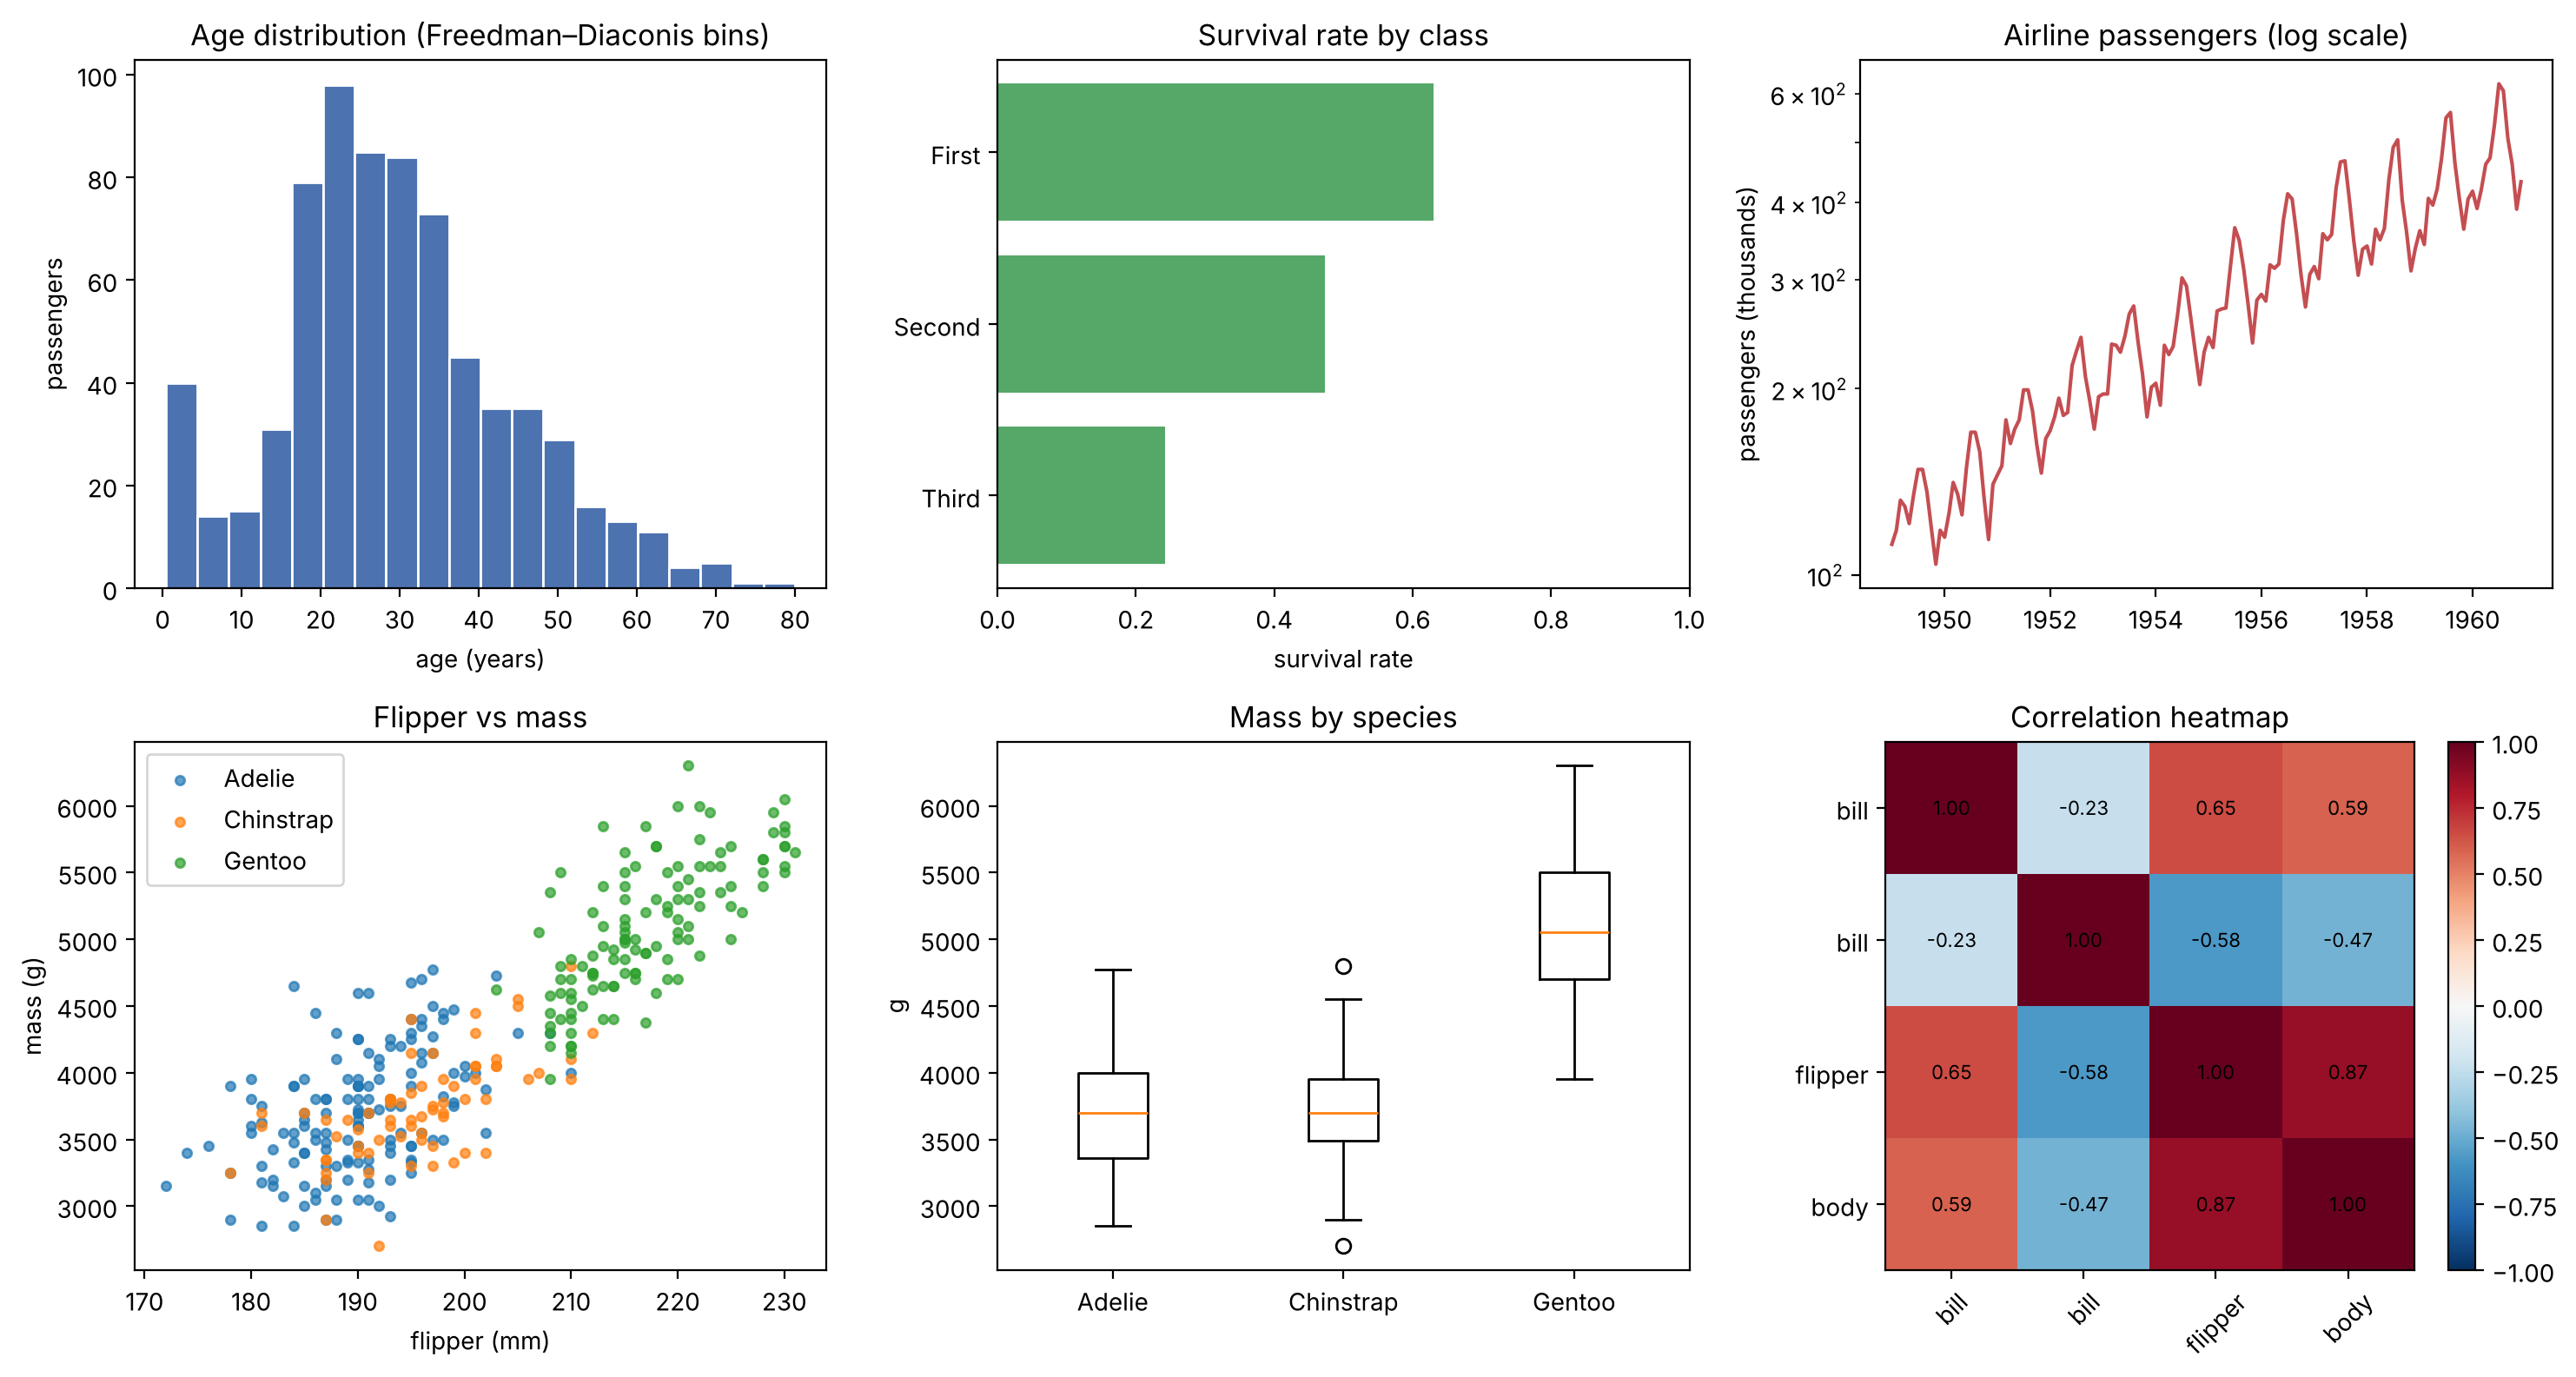

saved dashboard.png 183 KB
plotly html written: True


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
ax = axes[0, 0]; ax.hist(t.age.dropna(), bins="fd", color="#4C72B0", edgecolor="white")
ax.set(title="Age distribution (Freedman–Diaconis bins)", xlabel="age (years)", ylabel="passengers")

rates = t.groupby("class", observed=True).survived.mean().sort_values()
ax = axes[0, 1]; ax.barh(rates.index.astype(str), rates.values, color="#55A868"); ax.set_xlim(0, 1)
ax.set(title="Survival rate by class", xlabel="survival rate")

ax = axes[0, 2]; ax.plot(fl.index, fl.passengers, color="#C44E52"); ax.set_yscale("log")
ax.set(title="Airline passengers (log scale)", ylabel="passengers (thousands)")

ax = axes[1, 0]
for sp, g in peng.groupby("species"):
    ax.scatter(g.flipper_length_mm, g.body_mass_g, label=sp, s=14, alpha=0.7)
ax.legend(); ax.set(title="Flipper vs mass", xlabel="flipper (mm)", ylabel="mass (g)")

ax = axes[1, 1]; ax.boxplot([g.body_mass_g for _, g in peng.groupby("species")], tick_labels=sorted(peng.species.unique()))
ax.set(title="Mass by species", ylabel="g")

corr = peng.select_dtypes("number").drop(columns="mass_rank", errors="ignore").corr()
ax = axes[1, 2]; im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), [c.split("_")[0] for c in corr.columns], rotation=45)
ax.set_yticks(range(len(corr)), [c.split("_")[0] for c in corr.columns]); fig.colorbar(im, ax=ax)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation heatmap")
fig.tight_layout(); out_png = tmp / "dashboard.png"; fig.savefig(out_png, dpi=110)
plt.show(); print("saved", out_png.name, out_png.stat().st_size // 1024, "KB")

try:                                              # optional interactive version
    import plotly.express as px
    pfig = px.scatter(peng, x="flipper_length_mm", y="body_mass_g", color="species", hover_data=["island", "sex"])
    pfig.write_html(tmp / "penguins.html", include_plotlyjs="cdn"); print("plotly html written:", (tmp / "penguins.html").exists())
except ImportError:
    print("plotly not installed - pip install plotly")

*Hindi summary:* एक 6-chart dashboard: age histogram, class-wise survival bar (0 से शुरू), log scale पर flights line, species रंग वाला scatter, boxplot, और correlation heatmap — फिर PNG में save। plotly से hover वाला interactive HTML।

**e. Traps.** Truncated y-axis on bars exaggerating differences. Rainbow colormaps for continuous data (use viridis/RdBu diverging around 0). Overplotting thousands of points (use alpha, hexbin). Pie charts with many slices. Interview: *"How would you show the relationship between 10 numeric features quickly?"* Correlation heatmap + pairplot of the top pairs, then scatter with colour by target.

**f. Memory.** Mnemonic **"D-C-T-R-M: Distribution→hist, Compare→bar, Time→line, Relation→scatter, Matrix→heatmap."** **याद रखो:** *"Bar हमेशा 0 से, और हर axis पर unit।"*

| Q | A |
|---|---|
| Trend over time? | Line chart |
| Bars must start at? | Zero |
| Two numeric variables? | Scatter |
| Diverging colormap for correlations? | RdBu (centred at 0) |
| Interactive charts? | plotly |

**g. Practice.** (1) Plot average tip % by day from `tips.csv` (sorted bar). (2) Plot flights as a month × year heatmap. (3) Make a histogram of log1p(fare) and compare shape to raw fare.

**Solutions / हल**

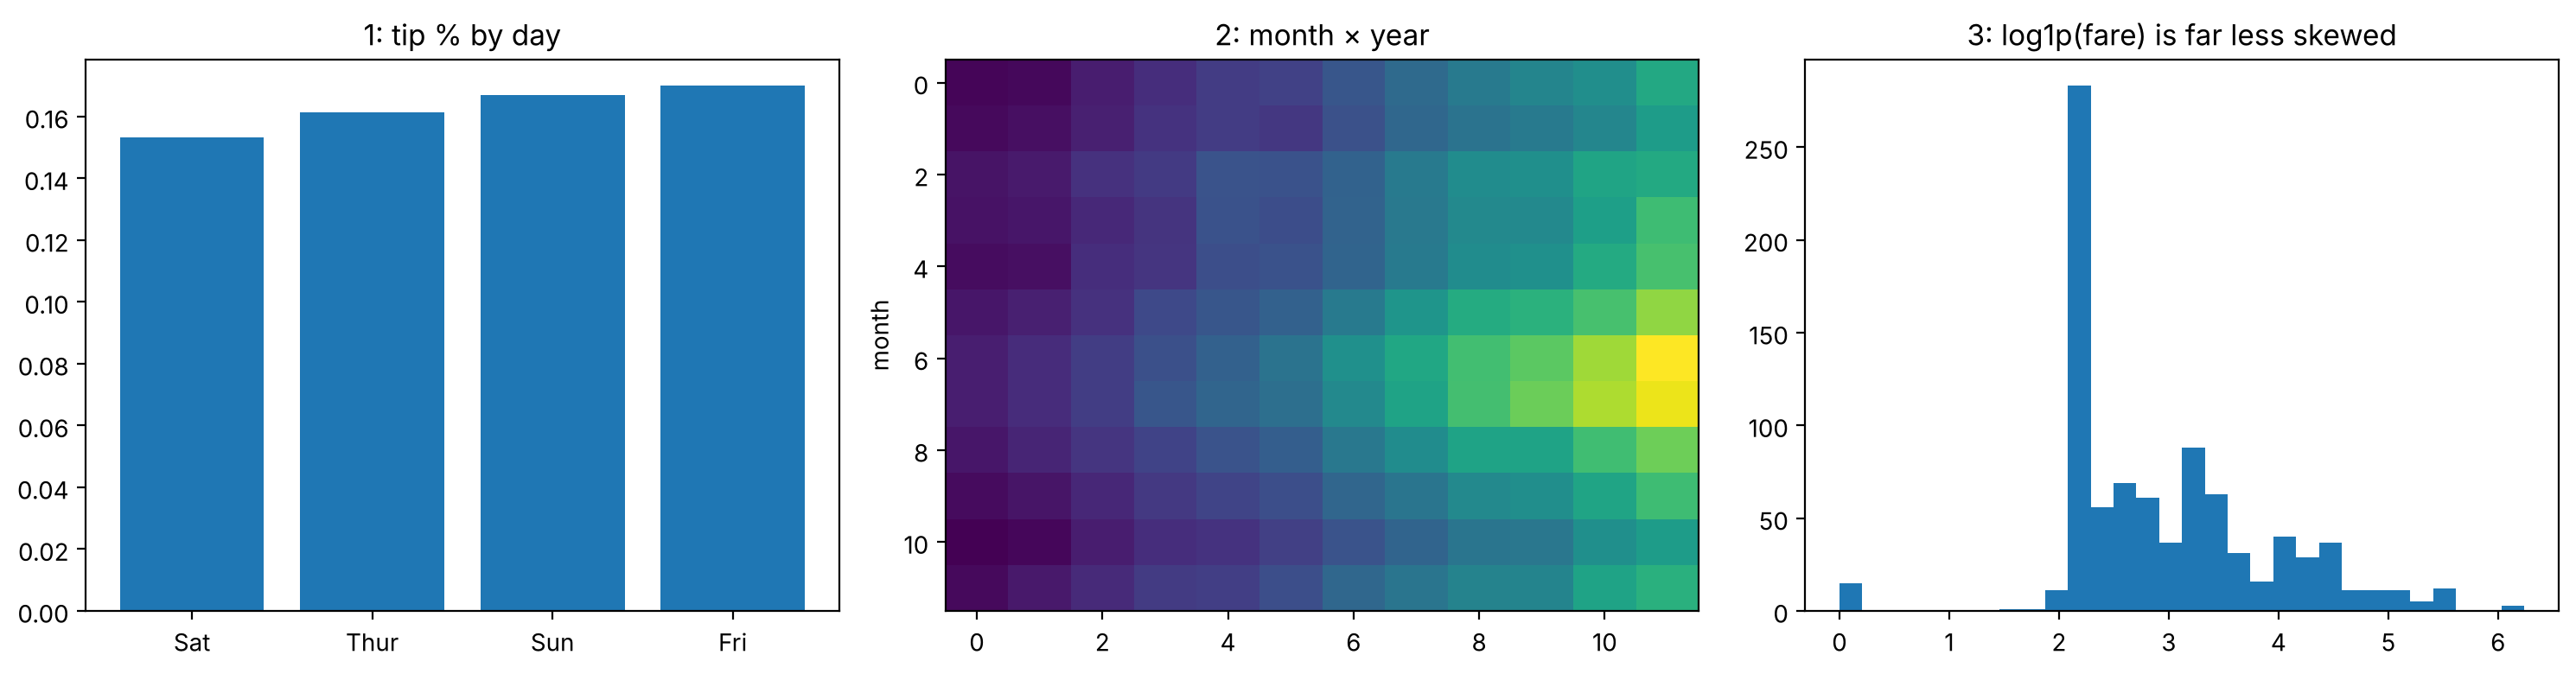

In [13]:
tips = pd.read_csv(DATA / "tips.csv"); tips["tip_pct"] = tips.tip / tips.total_bill
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
r = tips.groupby("day").tip_pct.mean().sort_values(); axs[0].bar(r.index, r.values); axs[0].set_title("1: tip % by day")
hm = fl.pivot_table(index=fl.index.month, columns=fl.index.year, values="passengers")
axs[1].imshow(hm, aspect="auto", cmap="viridis"); axs[1].set(title="2: month × year", ylabel="month")
axs[2].hist(np.log1p(t.fare), bins=30); axs[2].set_title("3: log1p(fare) is far less skewed")
fig.tight_layout(); plt.show()

**h. Quiz.** 1) Which chart for comparing 5 product sales? 2) What does a log y-axis do to exponential growth? 3) Why alpha in scatter plots? 4) When is a pie OK? 5) Best colormap for ordered values?

**Answers**1) Sorted bar. 2) Makes it a straight line. 3) Reveal density under overplotting. 4) ≤ 3 parts of a whole, roughly. 5) Sequential, perceptually uniform (viridis).

---

## ★ Mini-project — Complete Sales Analysis (load → clean → explore → visualize → insights)
### ★ Mini-project — पूरा Sales Analysis

**Business question:** *"Where is our revenue coming from, what is growing, and what should we do next quarter?"* The data is **synthetic** (seeded, generated below) so everyone gets identical numbers; it mimics a retail export with real-world mess: duplicates, missing values, bad prices, inconsistent text.

raw: (5040, 8)
clean: (4856, 10) | cities: ['Bengaluru', 'Delhi', 'Kolkata', 'Mumbai', 'Pune']
category
Electronics    92085000.0
Home           12710000.0
Fashion         5892000.0
Grocery         2080000.0
Name: revenue, dtype: float64
       category  product_id         rev  rnk
0   Electronics           3  25737017.0    1
5       Fashion          13   2045214.0    1
10      Grocery          10    599065.0    1
15         Home          20   4853461.0    1


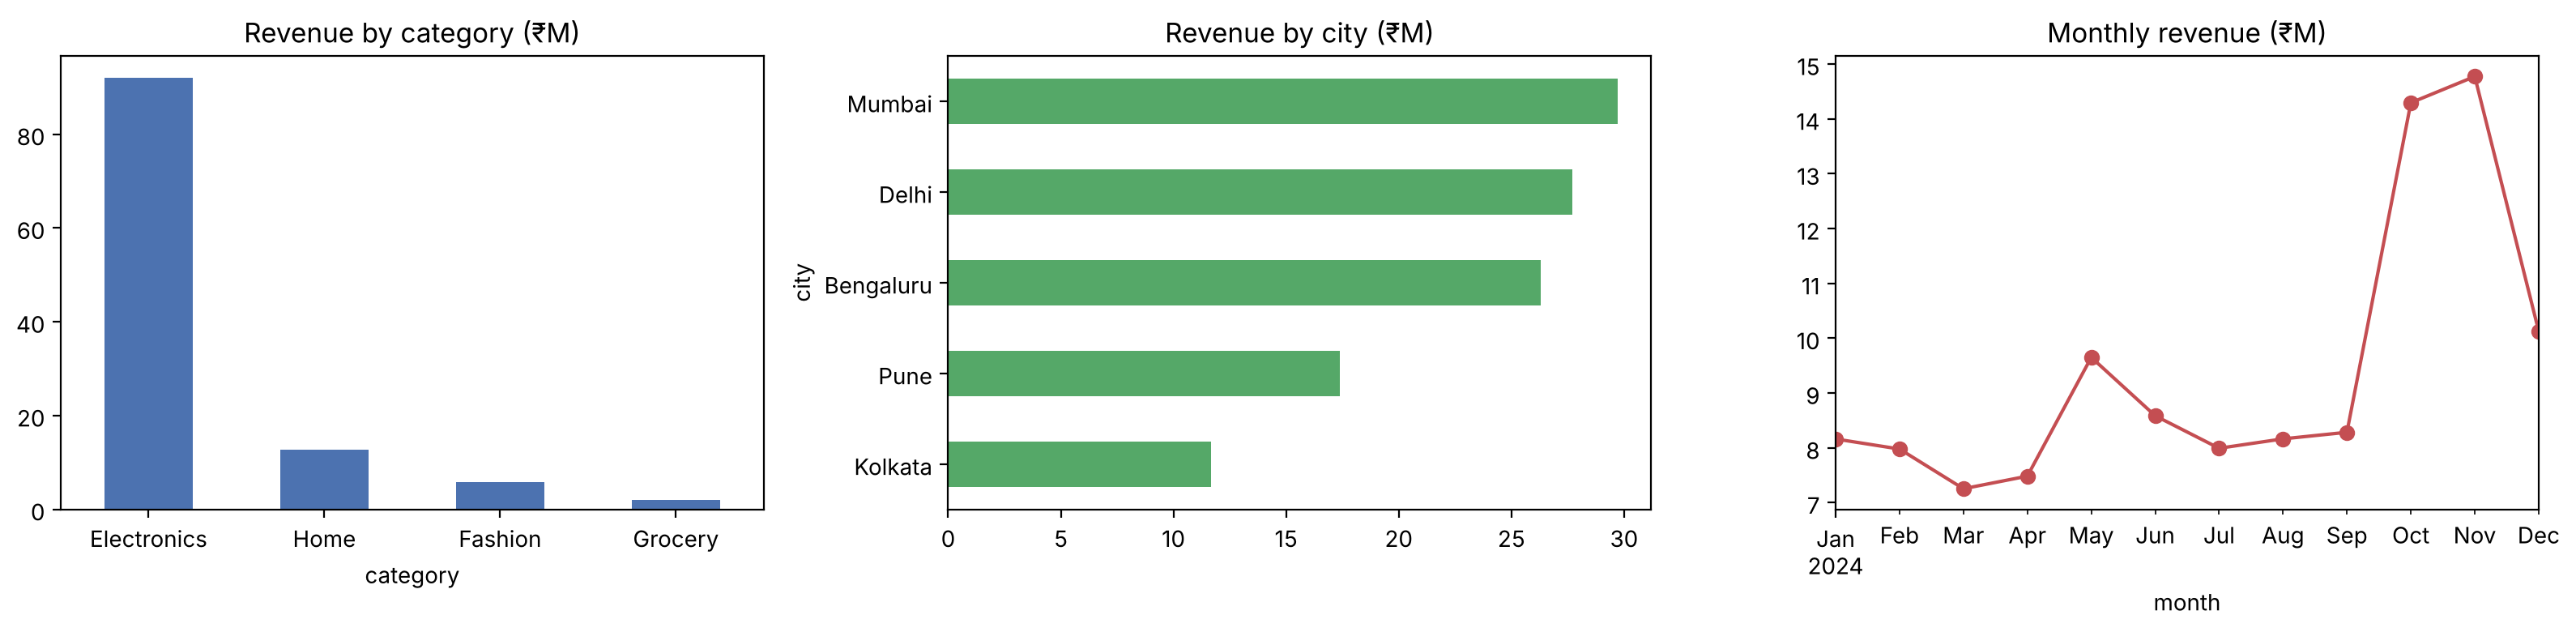


INSIGHT REPORT — FY2024 (synthetic data)
1. Electronics drives 82% of revenue; Grocery only 1.8%.
2. Oct–Nov (festive) = 26% of annual revenue vs 16.7% if flat → stock up and staff up in September.
3. Top city Mumbai = 26% of revenue; Kolkata lowest → test a local campaign.
4. Average order value ₹23,222; best month 2024-11 (₹14.8M).
5. Data quality: 184 of 5040 raw rows removed (dupes, bad prices, missing qty) → fix the export at source.



In [14]:
# 1) GENERATE + LOAD (simulating a messy export)
n = 5000
products = pd.DataFrame({"product_id": range(1, 21),
                         "category": np.repeat(["Electronics", "Grocery", "Fashion", "Home"], 5),
                         "base_price": np.round(np.r_[rng.uniform(5000, 40000, 5), rng.uniform(50, 800, 5),
                                                     rng.uniform(500, 4000, 5), rng.uniform(800, 9000, 5)], 0)})
dates = pd.to_datetime("2024-01-01") + pd.to_timedelta(rng.integers(0, 366, n), unit="D")
orders = pd.DataFrame({"order_id": np.arange(100001, 100001 + n), "date": dates,
                       "product_id": rng.integers(1, 21, n),
                       "city": rng.choice(["Mumbai", "Delhi", "Bengaluru", "Pune", "Kolkata"], n, p=[.28, .25, .22, .15, .10]),
                       "qty": rng.integers(1, 6, n)})
festive = orders.date.dt.month.isin([10, 11])                          # Diwali-season boost
orders.loc[festive, "qty"] *= 2                                         # festive demand doubles
orders = orders.merge(products, on="product_id")
orders["unit_price"] = (orders.base_price * rng.uniform(0.85, 1.1, n)).round(0)
orders["unit_price"] = orders.unit_price.where(rng.random(n) > 0.01, -1)                 # 1% bad prices
orders["city"] = orders.city.where(rng.random(n) > 0.05, orders.city.str.lower() + " ")  # 5% messy text
orders.loc[rng.random(n) < 0.02, "qty"] = np.nan                                          # 2% missing qty
orders = pd.concat([orders, orders.sample(40, random_state=3)])                           # duplicates
print("raw:", orders.shape)

# 2) CLEAN
sales = (orders.drop_duplicates(subset="order_id")
               .assign(city=lambda d: d.city.str.strip().str.title(),
                       unit_price=lambda d: d.unit_price.mask(d.unit_price <= 0))
               .dropna(subset=["qty", "unit_price"])
               .assign(qty=lambda d: d.qty.astype(int),
                       revenue=lambda d: d.qty * d.unit_price,
                       month=lambda d: d.date.dt.to_period("M")))
print("clean:", sales.shape, "| cities:", sorted(sales.city.unique()))

# 3) EXPLORE (pandas + the same thing in SQL)
by_cat = sales.groupby("category").revenue.sum().sort_values(ascending=False)
by_city = sales.groupby("city").revenue.sum().sort_values(ascending=False)
monthly = sales.groupby("month").revenue.sum()
con2 = sqlite3.connect(":memory:"); sales.assign(month=sales.month.astype(str), date=sales.date.astype(str)).to_sql("sales", con2, index=False)
top_products = pd.read_sql_query("""
    WITH p AS (SELECT category, product_id, SUM(revenue) rev FROM sales GROUP BY category, product_id)
    SELECT category, product_id, ROUND(rev) rev,
           RANK() OVER (PARTITION BY category ORDER BY rev DESC) rnk FROM p""", con2).query("rnk == 1")
print(by_cat.round(-3)); print(top_products)

# 4) VISUALIZE
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
(by_cat / 1e6).plot.bar(ax=axs[0], color="#4C72B0", title="Revenue by category (₹M)", rot=0)
(by_city / 1e6).sort_values().plot.barh(ax=axs[1], color="#55A868", title="Revenue by city (₹M)")
(monthly / 1e6).plot(ax=axs[2], marker="o", color="#C44E52", title="Monthly revenue (₹M)")
fig.tight_layout(); plt.show()

# 5) INSIGHT REPORT (computed, not hand-typed)
fest_share = sales[sales.date.dt.month.isin([10, 11])].revenue.sum() / sales.revenue.sum()
aov = sales.revenue.mean()
cat_share = (by_cat / by_cat.sum()).round(3)
report = f"""
INSIGHT REPORT — FY2024 (synthetic data)
1. {by_cat.index[0]} drives {cat_share.iloc[0]:.0%} of revenue; {by_cat.index[-1]} only {cat_share.iloc[-1]:.1%}.
2. Oct–Nov (festive) = {fest_share:.0%} of annual revenue vs 16.7% if flat → stock up and staff up in September.
3. Top city {by_city.index[0]} = {by_city.iloc[0]/by_city.sum():.0%} of revenue; {by_city.index[-1]} lowest → test a local campaign.
4. Average order value ₹{aov:,.0f}; best month {monthly.idxmax()} (₹{monthly.max()/1e6:.1f}M).
5. Data quality: {len(orders) - len(sales)} of {len(orders)} raw rows removed (dupes, bad prices, missing qty) → fix the export at source.
"""
print(report)

*Hindi summary:* Messy sales data बनाया (duplicates, गलत prices, गड़बड़ city names), साफ़ किया, pandas और SQL (CTE + RANK) से explore किया, 3 charts बनाए, और 5 insights वाली report सीधे numbers से generate की — त्योहार के महीने (Oct–Nov) में revenue बहुत ज़्यादा।

---

## Module 4 cheat sheet

| Task | pandas | SQL |
|---|---|---|
| Filter rows | `df[(a) & (b)]`, `query` | `WHERE` |
| Select columns | `df[["a","b"]]` | `SELECT a, b` |
| Group summary | `groupby().agg(n=("x","size"))` | `GROUP BY` + `HAVING` |
| Join | `merge(validate=)` | `JOIN … ON` |
| Per-row group value | `groupby().transform()` | `… OVER (PARTITION BY)` |
| Top-N per group | `sort_values` + `groupby().head(n)` | `ROW_NUMBER()` in a CTE |
| Reshape | `pivot_table`, `melt` | `CASE WHEN` pivots |
| Speed | vectorize, `category`, Parquet | indexes, `EXPLAIN` |

**याद रखो:** *Slice = view · Mask में & · Merge से पहले validate · WHERE rows, HAVING groups · Bar 0 से।*

## Spaced repetition plan

| Review | Task |
|---|---|
| Day 1 | Flashcards; rewrite the broadcasting standardisation and one window-function query from memory |
| Day 3 | Redo Lesson 4.4 Hard exercise; explain row explosion in Hindi |
| Day 7 | All quizzes; re-create the 6-chart dashboard from a blank notebook |
| Day 21 | Repeat the sales analysis with a different seed — do insights change? |
| Day 60 | Re-do the sales analysis entirely in SQL (except charts) |

## Sources

- NumPy user guide (broadcasting, indexing): https://numpy.org/doc/stable/user/basics.broadcasting.html · https://numpy.org/doc/stable/user/basics.indexing.html
- pandas user guide: https://pandas.pydata.org/docs/user_guide/index.html · Copy-on-Write: https://pandas.pydata.org/docs/user_guide/copy_on_write.html · groupby: https://pandas.pydata.org/docs/user_guide/groupby.html · merging: https://pandas.pydata.org/docs/user_guide/merging.html
- SQLite: SELECT https://www.sqlite.org/lang_select.html · window functions https://www.sqlite.org/windowfunctions.html · query planner https://www.sqlite.org/queryplanner.html
- Python sqlite3 placeholders: https://docs.python.org/3/library/sqlite3.html#sqlite3-placeholders · OWASP SQL injection: https://owasp.org/www-community/attacks/SQL_Injection
- matplotlib: https://matplotlib.org/stable/users/explain/quick_start.html · colormaps: https://matplotlib.org/stable/users/explain/colors/colormaps.html · plotly express: https://plotly.com/python/plotly-express/
- Apache Parquet: https://parquet.apache.org/docs/